# Sub-Metric: Schools

## Question: Which Pittsburgh neighborhood has the best access to schools, both primary and secondary?

In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv("/Users/EpicE/School/CMPINF 0011/Final Project/data_with_neighborhood.csv")

print(data.shape)
print(data.columns)
data.head(5)

(410, 33)
Index(['X', 'Y', 'OBJECTID', 'LEA_AUN', 'LEA_AIU_Description', 'LEA_Inst_Name',
       'School_Name', 'City', 'State', 'Zipcode', 'Full_Address', 'Grade_List',
       'Elementary', 'Secondary', 'Grade_K', 'Grade_1', 'Grade_2', 'Grade_3',
       'Grade_4', 'Grade_5', 'Grade_6', 'Grade_7', 'Grade_8', 'Grade_9',
       'Grade_10', 'Grade_11', 'Grade_12', 'Cyber_School', 'Last_Edit_Date',
       'School_Category', 'School_Category_Description', 'Address',
       'Pittsburgh_Neighborhood'],
      dtype='str')


,X,Y,OBJECTID,LEA_AUN,LEA_AIU_Description,LEA_Inst_Name,School_Name,City,State,Zipcode,...,Grade_9,Grade_10,Grade_11,Grade_12,Cyber_School,Last_Edit_Date,School_Category,School_Category_Description,Address,Pittsburgh_Neighborhood
0,-8.906205e+06,4.950435e+06,2,103020407,Allegheny IU3,North Allegheny,A W Beattie Career Center,Allison Park,PA,15101,...,0,1,1,1,NaN,2025/11/14 14:06:54.965+00,OCCCTC,CTC,9600 Babcock Boulevard,NaN
1,-8.907557e+06,4.917556e+06,3,103021252,Allegheny IU3,Bethel Park,Abraham Lincoln El Sch,Pittsburgh,PA,15234,...,0,0,0,0,NaN,2025/11/10 20:01:25.620+00,SD,Public School,1524 Hamilton Road,NaN
2,-8.894558e+06,4.933163e+06,4,102027451,Pittsburgh-Mt. Oliver IU2,City of Pittsburgh,Pittsburgh Westinghouse Academy 6-12,Pittsburgh,PA,15208,...,1,1,1,1,NaN,2025/11/10 20:01:25.910+00,SD,Public School,1101 N Murtland Street,Homewood West
3,-8.885219e+06,4.945560e+06,5,103020603,Allegheny IU3,Allegheny Valley,Acmetonia El Sch,Cheswick,PA,15024,...,0,0,0,0,NaN,2025/11/10 20:01:26.214+00,SD,Public School,300 Pearl Street,NaN
4,-8.898741e+06,4.913079e+06,6,103000000,Allegheny IU3,West Jefferson Hills,Allegheny IU 3- Mon Valley,Jefferson Hills,PA,15025,...,1,1,1,1,NaN,2025/11/10 20:01:26.675+00,IU,Public School,555 N. Lewis Run Road,NaN


There are 410 total schools in Allegheny County, but we're only interested in those located in Pittsburgh. Let's filter it down and see how many are within city limits

In [5]:
print(data["City"].values)
print(data["City"].value_counts())

<StringArray>
[   'Allison Park',      'Pittsburgh',      'Pittsburgh',        'Cheswick',
 'Jefferson Hills',     'Bethel Park',     'Monroeville',      'Pittsburgh',
      'Pittsburgh',      'Pittsburgh',
 ...
      'Pittsburgh',    'Allison Park',      'Pittsburgh',      'Pittsburgh',
      'Pittsburgh',       'Sewickley',      'Pittsburgh',      'Pittsburgh',
    'West Mifflin',      'Pittsburgh']
Length: 410, dtype: str
City
Pittsburgh             220
Monroeville             15
Allison Park            12
McKeesport              12
Sewickley               11
Gibsonia                10
Bethel Park              9
Wexford                  9
West Mifflin             8
Moon Township            7
Bridgeville              6
McKees Rocks             6
Glenshaw                 6
Cheswick                 5
Jefferson Hills          5
Coraopolis               5
Natrona Heights          4
Munhall                  4
McDonald                 4
Elizabeth                3
Oakdale                  3

A total of 220 schools in Pittsburgh, let's prune out the ones that aren't.

In [6]:
pittsburgh_schools = data[data["City"].str.contains("Pittsburgh")]
print(pittsburgh_schools.shape)

(220, 33)


Now, let's take a look at the neighborhood breakdown

In [35]:
total = pittsburgh_schools["Pittsburgh_Neighborhood"].value_counts()
print(pittsburgh_schools["Pittsburgh_Neighborhood"].value_counts())

Pittsburgh_Neighborhood
Squirrel Hill South          7
Shadyside                    7
North Oakland                6
Squirrel Hill North          6
Central Business District    5
Point Breeze                 5
Allegheny Center             4
Brookline                    4
East Liberty                 4
Perry South                  4
Manchester                   3
Beechview                    3
Carrick                      3
Lower Lawrenceville          2
Highland Park                2
Larimer                      2
Bedford Dwellings            2
Brighton Heights             2
East Allegheny               2
Stanton Heights              2
Middle Hill                  2
Bloomfield                   2
Hazelwood                    2
Homewood West                1
Lincoln-Lemington-Belmar     1
Regent Square                1
Mt. Oliver                   1
Banksville                   1
Overbrook                    1
Crafton Heights              1
Homewood South               1
Allentown      

Only 6 neighborhoods have 5 or more schools, let's take a look at that breakdown between elementary and secondary schools as well.

In [39]:
cols = ["Elementary", "Secondary"]
summary = (
    pittsburgh_schools
    .groupby("Pittsburgh_Neighborhood")[cols]
    .apply(lambda d: (d == 1).sum())
)
summary["Total"] = summary.sum(axis=1)
print(summary.sort_values("Total", ascending=False))
rank = summary.sort_values("Total", ascending=False)

                           Elementary  Secondary  Total
Pittsburgh_Neighborhood                                
North Oakland                       5          5     10
Shadyside                           6          3      9
Squirrel Hill South                 6          3      9
Squirrel Hill North                 5          2      7
Perry South                         4          3      7
Central Business District           3          4      7
East Liberty                        3          3      6
Point Breeze                        5          0      5
Brookline                           4          1      5
Allegheny Center                    4          0      4
Manchester                          3          1      4
Stanton Heights                     2          1      3
Beechview                           2          1      3
Carrick                             2          1      3
Bloomfield                          2          0      2
Arlington                           1          1

Here, we see the breakdown of elementary and secondary schools has North Oakland with the highest total options of schooling at 10, although some schools get counted twice since they offer both elementary and secondary schooling. Based on this table, if you have younger kids, you could easily go to any of the top couple of neighborhoods since they all have a bunch of options. However, if you have kids in secondary school, some of the top neighborhoods don't have as many options. In fact, some neighborhoods like Point Breeze, for example, don't have any secondary schools at all. 

Let's visualize the breakdown of the table above with a graph depicting the available elementary and secondary schools in the top 10 neighborhoods to see how they fare against each other.

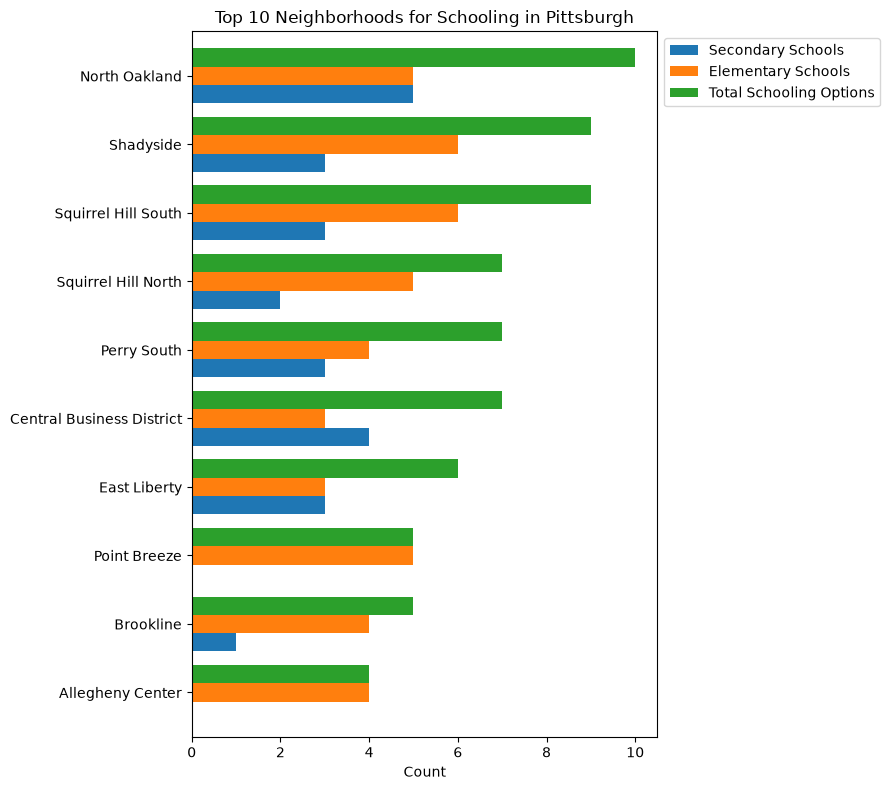

In [44]:
top10 = rank.head(10).iloc[::-1]

graph = top10[["Secondary", "Elementary", "Total"]].plot(
    kind="barh", figsize=(9, 8), width=0.8
)
graph.set_title("Top 10 Neighborhoods for Schooling in Pittsburgh")
graph.set_xlabel("Count")
graph.set_ylabel("")
graph.legend(["Secondary Schools", "Elementary Schools", "Total Schooling Options"], loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Based on this chart, North Oakland is the best neighborhood for being well rounded in terms of schooling options. In the top 10, Shadyside and Squirrel Hill South are tied for the most elementary schools with 6 while North Oakland has the most options for secondary schools with 5.